# Trabajo Final PIAD-427 – Clasificación de Dígitos Manuscritos (Caso TecnoForms)

**Estudiante:** Cáceres Ticona, Diego Daniel · **Curso:** PIAD-427 – SENATI


Pipeline completo: preprocesamiento y segmentación de formularios → modelos de referencia (regresión logística, KNN, SVM) y K-Means → CNN con validación cruzada → evaluación en test → demo end-to-end.

## 0. Instalación y configuración

In [25]:

#%pip install tensorflow scikit-learn opencv-python matplotlib numpy pandas

In [26]:
import argparse, json, os, random, time
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

QUICK = False        # True = prueba rápida | False = corrida completa
SEED = 42
OUT = "resultados"
os.makedirs(OUT, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
set_seed()
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.22.0-rc0 | GPU: []


## 1. Preprocesamiento y segmentación de formularios

Escala de grises → suavizado gaussiano → binarización (Otsu o adaptativa) → apertura morfológica → contornos → orden de lectura → normalización 28×28 estilo MNIST (lado mayor 20 px, centrado por centro de masa).

In [27]:
def to_gray(img):
    """Conversión a escala de grises."""
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img.copy()


def binarize(gray, adaptive=False):
    """Suavizado + binarización (tinta = 255, fondo = 0).
    Otsu para iluminación uniforme; adaptativa para fotos/escaneos con sombras."""
    gray = cv2.GaussianBlur(gray, (5, 5), 0)
    if adaptive:
        b = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY_INV, 31, 10)
    else:
        _, b = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # apertura morfológica: elimina ruido sal y pimienta
    return cv2.morphologyEx(b, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def normalize_digit(crop_bin):
    """Recorte binario -> imagen 28x28 estilo MNIST:
    lado mayor a 20 px, centrado por centro de masa en lienzo 28x28."""
    h, w = crop_bin.shape
    s = 20.0 / max(h, w)
    new_w, new_h = max(1, int(round(w * s))), max(1, int(round(h * s)))
    r = cv2.resize(crop_bin, (new_w, new_h), interpolation=cv2.INTER_AREA)
    canvas = np.zeros((28, 28), np.uint8)
    y0, x0 = (28 - new_h) // 2, (28 - new_w) // 2
    canvas[y0:y0 + new_h, x0:x0 + new_w] = r
    m = cv2.moments(canvas)
    if m["m00"] > 0:
        cx, cy = m["m10"] / m["m00"], m["m01"] / m["m00"]
        M = np.float32([[1, 0, 14 - cx], [0, 1, 14 - cy]])
        canvas = cv2.warpAffine(canvas, M, (28, 28))
    return canvas


def segment_digits(img, adaptive=False, min_area=60, row_tol=0.6, pad=4):
    """Segmenta dígitos de un formulario.
    Devuelve (lista de imágenes 28x28 float32 en [0,1], lista de cajas (x,y,w,h))
    ordenadas por filas (arriba->abajo) y dentro de cada fila izquierda->derecha."""
    gray = to_gray(img)
    binar = binarize(gray, adaptive)
    H, W = binar.shape
    cnts, _ = cv2.findContours(binar, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = [cv2.boundingRect(c) for c in cnts]
    # filtro de ruido y de objetos enormes (líneas, bordes de casillas)
    boxes = [b for b in boxes if b[2] * b[3] >= min_area
             and b[2] < 0.5 * W and b[3] < 0.5 * H]
    if not boxes:
        return [], []
    med_h = float(np.median([b[3] for b in boxes]))
    boxes.sort(key=lambda b: b[1] + b[3] / 2)
    rows, cur = [], [boxes[0]]
    for b in boxes[1:]:
        cy = b[1] + b[3] / 2
        row_cy = np.mean([c[1] + c[3] / 2 for c in cur])
        if abs(cy - row_cy) < row_tol * med_h:
            cur.append(b)
        else:
            rows.append(cur)
            cur = [b]
    rows.append(cur)
    ordered = [b for row in rows for b in sorted(row, key=lambda t: t[0])]
    digits = []
    for (x, y, w, h) in ordered:
        x0, y0 = max(0, x - pad), max(0, y - pad)
        crop = binar[y0:min(H, y + h + pad), x0:min(W, x + w + pad)]
        digits.append(normalize_digit(crop).astype("float32") / 255.0)
    return digits, ordered


def make_synthetic_form(digits, labels, per_row=8, scale=3, gap=45, seed=SEED):
    """Formulario sintético (tinta oscura sobre papel con ruido y gradiente de
    luz) para probar el pipeline sin necesitar escaneos reales."""
    rng = np.random.default_rng(seed)
    n = len(digits)
    rows = int(np.ceil(n / per_row))
    cell = 28 * scale + gap
    img = np.full((rows * cell + gap, per_row * cell + gap), 255, np.uint8)
    for i, d in enumerate(digits):
        r, c = divmod(i, per_row)
        tile = cv2.resize(255 - (d.squeeze() * 255).astype(np.uint8),
                          (28 * scale, 28 * scale), interpolation=cv2.INTER_LINEAR)
        y = gap + r * cell + int(rng.integers(-6, 7))
        x = gap + c * cell + int(rng.integers(-6, 7))
        img[y:y + 28 * scale, x:x + 28 * scale] = np.minimum(
            img[y:y + 28 * scale, x:x + 28 * scale], tile)
    grad = np.linspace(0, 35, img.shape[1])[None, :]
    noise = rng.normal(0, 6, img.shape)
    img = np.clip(img.astype(float) - grad + noise, 0, 255).astype(np.uint8)
    return img, list(labels)

## 2. Datos (MNIST) y utilidades de evaluación

60 000 imágenes de entrenamiento y 10 000 de test (28×28, escala de grises). El conjunto de **test se reserva** para la evaluación final.

In [28]:
def load_data():
    (x_tr, y_tr), (x_te, y_te) = keras.datasets.mnist.load_data()
    x_tr = (x_tr.astype("float32") / 255.0)[..., None]   # normalización [0,1]
    x_te = (x_te.astype("float32") / 255.0)[..., None]
    return x_tr, y_tr, x_te, y_te


def metrics_row(name, y_true, y_pred, extra=None):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro",
                                                 zero_division=0)
    row = {"modelo": name, "accuracy": float(accuracy_score(y_true, y_pred)),
           "precision_macro": float(p), "recall_macro": float(r),
           "f1_macro": float(f)}
    if extra:
        row.update(extra)
    return row


def save_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, fname), dpi=140)
    plt.show()
    plt.close(fig)

train: (60000, 28, 28, 1) | test: (10000, 28, 28, 1)
Distribución de clases (train): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


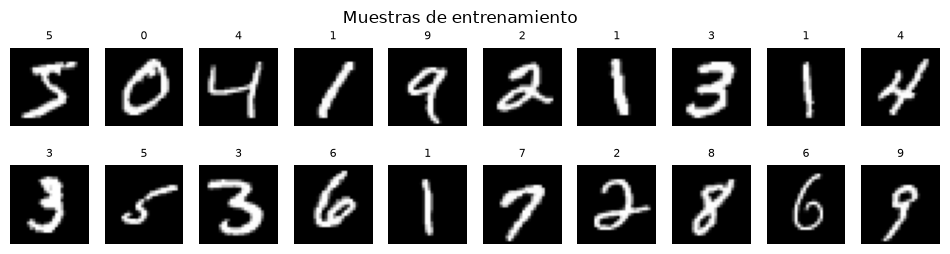

In [29]:
x_tr, y_tr, x_te, y_te = load_data()
print("train:", x_tr.shape, "| test:", x_te.shape)
print("Distribución de clases (train):", np.bincount(y_tr))

fig, axs = plt.subplots(2, 10, figsize=(12, 2.8))
for i, ax in enumerate(axs.ravel()):
    ax.imshow(x_tr[i].squeeze(), cmap="gray"); ax.set_title(int(y_tr[i]), fontsize=8); ax.axis("off")
plt.suptitle("Muestras de entrenamiento"); plt.show()

## 3. Modelos de referencia y K-Means

Regresión logística (línea base), KNN (k = 3) y SVM RBF; KNN y SVM sobre PCA de 50 componentes. Validación cruzada estratificada de 5 particiones. K-Means (k = 10) se usa como análisis exploratorio no supervisado.

In [30]:
def run_classical(x_tr, y_tr, x_te, y_te, cv_n, quick):
    flat_tr, flat_te = x_tr.reshape(len(x_tr), -1), x_te.reshape(len(x_te), -1)
    pca = PCA(n_components=50, random_state=SEED).fit(flat_tr)
    z_tr, z_te = pca.transform(flat_tr), pca.transform(flat_te)

    models = {
        "Regresión logística (softmax)": LogisticRegression(max_iter=300, C=0.5),
        "KNN (k=3, PCA-50)": KNeighborsClassifier(n_neighbors=3, weights="distance",
                                                  n_jobs=-1),
        "SVM RBF (PCA-50)": SVC(kernel="rbf", C=5, gamma="scale"),
    }
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    idx = np.random.RandomState(SEED).permutation(len(z_tr))[:cv_n]
    rows = []
    for name, model in models.items():
        t0 = time.time()
        X = z_tr if "PCA" in name else flat_tr
        Xte = z_te if "PCA" in name else flat_te
        cv = cross_val_score(model, X[idx], y_tr[idx], cv=skf, n_jobs=-1)
        n_fit = 10000 if quick else len(X)
        model.fit(X[:n_fit], y_tr[:n_fit])
        pred = model.predict(Xte)
        rows.append(metrics_row(name, y_te, pred, {
            "cv_acc_mean": float(cv.mean()), "cv_acc_std": float(cv.std()),
            "seg": round(time.time() - t0, 1)}))
        save_confusion(y_te, pred, name, f"cm_{name.split()[0].lower()}.png")
        print(f"[{name}] CV={cv.mean():.4f}±{cv.std():.4f}  test={rows[-1]['accuracy']:.4f}")

    # --- K-Means (no supervisado): ¿los dígitos forman 10 clusters naturales? ---
    km = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit(z_tr)
    mapping = {c: np.bincount(y_tr[km.labels_ == c]).argmax() for c in range(10)}
    pred_km = np.array([mapping[c] for c in km.predict(z_te)])
    rows.append(metrics_row("K-Means (k=10, exploratorio)", y_te, pred_km))
    print(f"[K-Means] acc (cluster->etiqueta mayoritaria)={rows[-1]['accuracy']:.4f}")
    save_confusion(y_te, pred_km, "K-Means (cluster -> etiqueta mayoritaria)", "cm_kmeans.png")

    # centroides: lo que "ve" K-Means
    fig, axs = plt.subplots(2, 5, figsize=(8, 3.6))
    cent = pca.inverse_transform(km.cluster_centers_)
    for c, ax in enumerate(axs.ravel()):
        ax.imshow(cent[c].reshape(28, 28), cmap="gray")
        ax.set_title(f"cluster {c}→{mapping[c]}", fontsize=8)
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, "kmeans_centroides.png"), dpi=140)
    plt.show()
    plt.close(fig)
    return rows

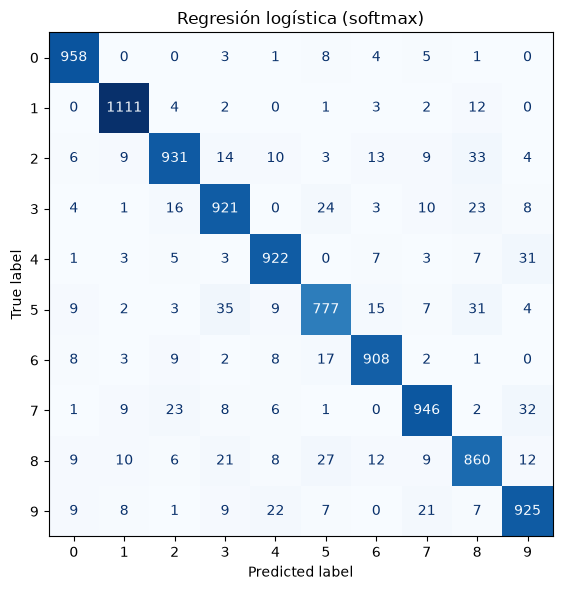

[Regresión logística (softmax)] CV=0.9035±0.0055  test=0.9259


KeyboardInterrupt: 

In [31]:
rows = run_classical(x_tr, y_tr, x_te, y_te, cv_n=5000 if QUICK else 10000, quick=QUICK)

## 4. Red Neuronal Convolucional (CNN)

Arquitectura: aumento de datos → [Conv-BN-Conv-Pool-Dropout] ×2 (32 y 64 filtros) → Flatten → Dense 128 → Dropout 0,5 → Softmax 10. Optimizador Adam, pérdida entropía cruzada categórica dispersa. Hiperparámetros por **búsqueda aleatoria con validación cruzada estratificada**.

In [ ]:
def build_cnn(base_filters=32, dense_units=128, dropout=0.5, lr=1e-3, augment=True):
    """Arquitectura: [Conv-Conv-Pool]x2 -> Flatten -> Dense -> Softmax."""
    f = base_filters
    inp = keras.Input((28, 28, 1))
    x = inp
    if augment:  # aumento de datos (solo activo en entrenamiento)
        x = layers.RandomRotation(0.04)(x)   # ±0.04·360° ≈ ±14°
        x = layers.RandomTranslation(0.1, 0.1)(x)
        x = layers.RandomZoom(0.1)(x)
    for mult, drop in ((1, 0.25), (2, 0.25)):
        x = layers.Conv2D(f * mult, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(f * mult, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(drop)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inp, out, name="cnn_digitos")
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def cv_search(x, y, n_configs, k=3, epochs=4):
    """Búsqueda aleatoria de hiperparámetros con validación cruzada estratificada."""
    space = {"base_filters": [16, 32], "dense_units": [64, 128, 256],
             "dropout": [0.3, 0.5], "lr": [1e-3, 5e-4, 3e-4]}
    rng = random.Random(SEED)
    cfgs, seen = [], set()
    while len(cfgs) < n_configs:
        c = {k_: rng.choice(v) for k_, v in space.items()}
        key = tuple(c.items())
        if key not in seen:
            seen.add(key)
            cfgs.append(c)
    skf = StratifiedKFold(k, shuffle=True, random_state=SEED)
    results = []
    for cfg in cfgs:
        accs = []
        for tr, va in skf.split(x, y):
            m = build_cnn(**cfg)
            m.fit(x[tr], y[tr], epochs=epochs, batch_size=128, verbose=0)
            accs.append(m.evaluate(x[va], y[va], verbose=0)[1])
            keras.backend.clear_session()
        res = {**cfg, "cv_acc": float(np.mean(accs)), "cv_std": float(np.std(accs))}
        results.append(res)
        print("  CV", res)
    return sorted(results, key=lambda r: -r["cv_acc"])


def plot_history(h, fname):
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, k, t in ((axs[0], "loss", "Pérdida"), (axs[1], "accuracy", "Exactitud")):
        ax.plot(h.history[k], label="train")
        ax.plot(h.history["val_" + k], label="val")
        ax.set_title(t); ax.set_xlabel("época"); ax.legend(); ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, fname), dpi=140)
    plt.show()
    plt.close(fig)


def plot_predictions(x, y_true, y_pred, fname, n=25):
    """Predicciones vs etiquetas reales (rojo = error)."""
    idx = np.arange(n)
    wrong = np.where(y_true != y_pred)[0][:10]
    if len(wrong):
        idx = np.concatenate([np.arange(n - len(wrong)), wrong])
    fig, axs = plt.subplots(5, 5, figsize=(7, 7.5))
    for ax, i in zip(axs.ravel(), idx):
        ax.imshow(x[i].squeeze(), cmap="gray")
        ok = y_true[i] == y_pred[i]
        ax.set_title(f"real {y_true[i]} | pred {y_pred[i]}", fontsize=8,
                     color="green" if ok else "red")
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, fname), dpi=140)
    plt.show()
    plt.close(fig)


def run_cnn(x_tr, y_tr, x_te, y_te, quick):
    n_cv = 6000 if quick else 12000
    n_cfg = 3 if quick else 8
    epochs_final = 4 if quick else 30
    sub = np.random.RandomState(SEED).permutation(len(x_tr))[:n_cv]
    print(f"\nBúsqueda de hiperparámetros ({n_cfg} configs, 3-fold CV, {n_cv} imágenes)")
    search = cv_search(x_tr[sub], y_tr[sub], n_cfg, epochs=3 if quick else 4)
    best = {k: search[0][k] for k in ("base_filters", "dense_units", "dropout", "lr")}
    print("Mejor configuración:", best)

    # validación hold-out (10 %) para early stopping del modelo final
    rs = np.random.RandomState(SEED).permutation(len(x_tr))
    n_val = len(x_tr) // 10
    va, tr = rs[:n_val], rs[n_val:]
    model = build_cnn(**best)
    model.summary()
    cbs = [keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True,
                                         monitor="val_accuracy"),
           keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-5)]
    hist = model.fit(x_tr[tr], y_tr[tr], validation_data=(x_tr[va], y_tr[va]),
                     epochs=epochs_final, batch_size=128, callbacks=cbs, verbose=2)
    plot_history(hist, "curvas_entrenamiento.png")

    prob = model.predict(x_te, verbose=0)
    pred = prob.argmax(1)
    print("\n=== CNN: reporte en TEST ===")
    rep = classification_report(y_te, pred, digits=4)
    print(rep)
    with open(os.path.join(OUT, "reporte_cnn.txt"), "w", encoding="utf-8") as f:
        f.write(rep)
    save_confusion(y_te, pred, "CNN - matriz de confusión (test)", "cm_cnn.png")
    plot_predictions(x_te, y_te, pred, "predicciones_cnn.png")
    model.save(os.path.join(OUT, "cnn_digitos.keras"))
    with open(os.path.join(OUT, "arquitectura_cnn.txt"), "w", encoding="utf-8") as f:
        model.summary(print_fn=lambda s: f.write(s + "\n"))
    with open(os.path.join(OUT, "busqueda_hiperparametros.json"), "w", encoding="utf-8") as f:
        json.dump(search, f, indent=2)
    try:
        keras.utils.plot_model(model, os.path.join(OUT, "arquitectura_cnn.png"),
                               show_shapes=True, show_layer_names=True)
    except Exception as e:  # requiere graphviz
        print("(plot_model omitido:", e, ")")
    row = metrics_row("CNN (Conv x4 + Dense)", y_te, pred,
                      {"cv_acc_mean": search[0]["cv_acc"], "cv_acc_std": search[0]["cv_std"]})
    return row, model


Búsqueda de hiperparámetros (8 configs, 3-fold CV, 12000 imágenes)
  CV {'base_filters': 16, 'dense_units': 64, 'dropout': 0.5, 'lr': 0.001, 'cv_acc': 0.6567499935626984, 'cv_std': 0.17681640247033306}
  CV {'base_filters': 16, 'dense_units': 64, 'dropout': 0.3, 'lr': 0.0003, 'cv_acc': 0.6427500049273173, 'cv_std': 0.0803914971158814}
  CV {'base_filters': 16, 'dense_units': 256, 'dropout': 0.5, 'lr': 0.001, 'cv_acc': 0.4205833474795024, 'cv_std': 0.14138575863115901}
  CV {'base_filters': 16, 'dense_units': 64, 'dropout': 0.3, 'lr': 0.001, 'cv_acc': 0.8263333241144816, 'cv_std': 0.06393823407579323}
  CV {'base_filters': 16, 'dense_units': 256, 'dropout': 0.3, 'lr': 0.0003, 'cv_acc': 0.2785833353797595, 'cv_std': 0.22338796199885075}
  CV {'base_filters': 32, 'dense_units': 64, 'dropout': 0.5, 'lr': 0.0003, 'cv_acc': 0.47716668248176575, 'cv_std': 0.2387464190907479}
  CV {'base_filters': 32, 'dense_units': 64, 'dropout': 0.3, 'lr': 0.0003, 'cv_acc': 0.5175000031789144, 'cv_std': 0.2

Model: "cnn_digitos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 117,626 (459.48 KB)

 Trainable params: 117,530 (459.10 KB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/30
422/422 - 30s - 70ms/step - accuracy: 0.7118 - loss: 0.8547 - val_accuracy: 0.9157 - val_loss: 0.3444 - learning_rate: 0.0010
Epoch 2/30
422/422 - 25s - 59ms/step - accuracy: 0.9076 - loss: 0.3051 - val_accuracy: 0.9768 - val_loss: 0.0786 - learning_rate: 0.0010
Epoch 3/30
422/422 - 24s - 56ms/step - accuracy: 0.9391 - loss: 0.2070 - val_accuracy: 0.9787 - val_loss: 0.0735 - learning_rate: 0.0010
Epoch 4/30
422/422 - 24s - 56ms/step - accuracy: 0.9534 - loss: 0.1597 - val_accuracy: 0.9820 - val_loss: 0.0654 - learning_rate: 0.0010
Epoch 5/30
422/422 - 24s - 56ms/step - accuracy: 0.9624 - loss: 0.1273 - val_accuracy: 0.9818 - val_loss: 0.0614 - learning_rate: 0.0010
Epoch 6/30
422/422 - 41s - 98ms/step - accuracy: 0.9651 - loss: 0.1188 - val_accuracy: 0.9790 - val_loss: 0.0712 - learning_rate: 0.0010
Epoch 7/30
422/422 - 24s - 57ms/step - accuracy: 0.9698 - loss: 0.1009 - val_accuracy: 0.9893 - val_loss: 0.0414 - learning_rate: 0.0010
Epoch 8/30
422/422 - 23s - 56ms/step - ac

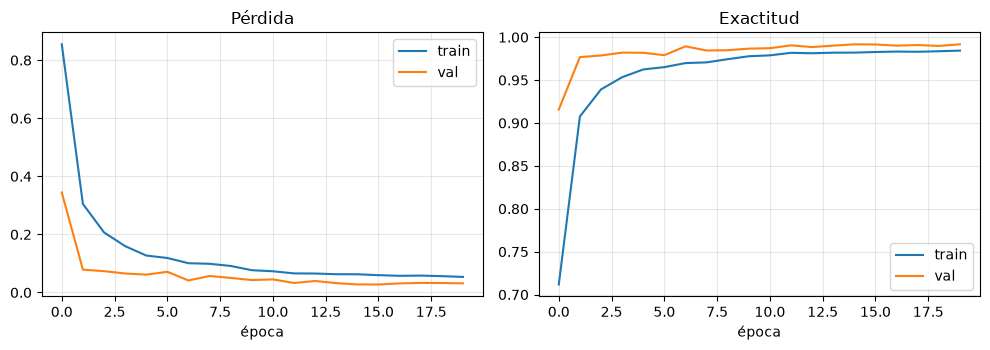


=== CNN: reporte en TEST ===
              precision    recall  f1-score   support

           0     0.9939    0.9959    0.9949       980
           1     0.9956    0.9859    0.9907      1135
           2     0.9865    0.9932    0.9899      1032
           3     0.9892    0.9950    0.9921      1010
           4     0.9899    0.9969    0.9934       982
           5     0.9921    0.9899    0.9910       892
           6     0.9927    0.9906    0.9916       958
           7     0.9912    0.9844    0.9878      1028
           8     0.9918    0.9969    0.9944       974
           9     0.9950    0.9901    0.9925      1009

    accuracy                         0.9918     10000
   macro avg     0.9918    0.9919    0.9918     10000
weighted avg     0.9918    0.9918    0.9918     10000



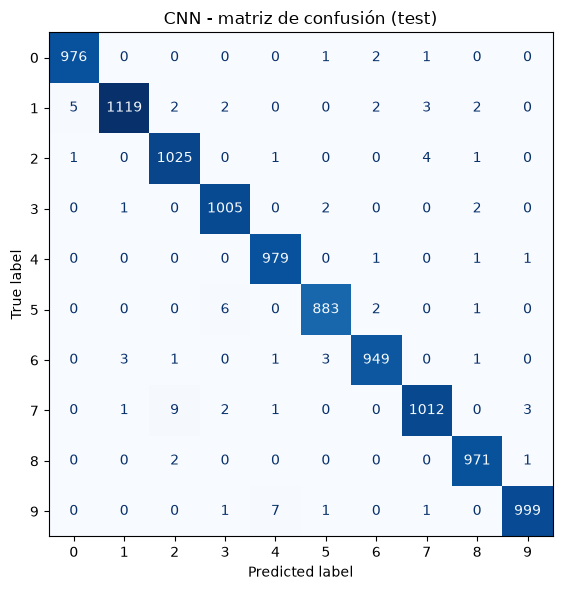

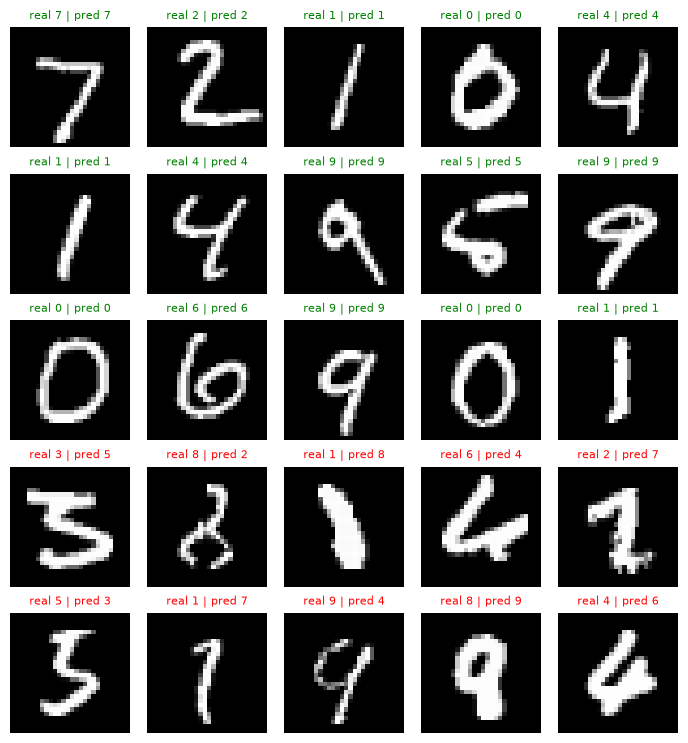

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [ ]:
cnn_row, model = run_cnn(x_tr, y_tr, x_te, y_te, QUICK)
rows.append(cnn_row)

## 5. Comparación de modelos (test)

,accuracy,precision_macro,recall_macro,f1_macro
modelo,,,,
CNN (Conv x4 + Dense),0.9918,0.9918,0.9919,0.9918
SVM RBF (PCA-50),0.9868,0.9867,0.9867,0.9867
"KNN (k=3, PCA-50)",0.9760,0.9759,0.9757,0.9758
Regresión logística (softmax),0.9259,0.9250,0.9248,0.9248
"K-Means (k=10, exploratorio)",0.5945,0.5035,0.5844,0.5332


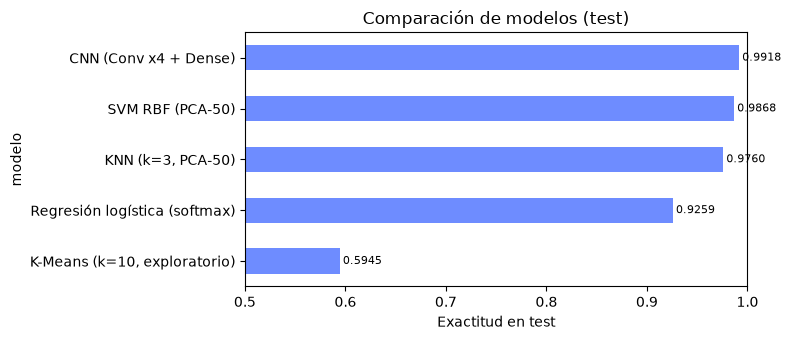

In [ ]:
df = pd.DataFrame(rows).set_index("modelo")
cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
tabla = df[cols].sort_values("accuracy", ascending=False).round(4)
display(tabla)

ax = tabla["accuracy"].plot(kind="barh", figsize=(8, 3.5), color="#6E8CFF")
ax.invert_yaxis(); ax.set_xlabel("Exactitud en test")
ax.set_xlim(min(0.5, tabla["accuracy"].min() - 0.05), 1.0)
for i, v in enumerate(tabla["accuracy"]):
    ax.text(v + 0.003, i, f"{v:.4f}", va="center", fontsize=8)
plt.title("Comparación de modelos (test)"); plt.tight_layout(); plt.show()

with open(os.path.join(OUT, "comparacion_modelos.json"), "w", encoding="utf-8") as f:
    json.dump(rows, f, indent=2, ensure_ascii=False)

## 6. Interpretación de resultados
- ¿La CNN supera a SVM y KNN? ¿Por cuántos puntos?
Evaluados sobre los 10 000 dígitos de test (corrida completa), la CNN obtuvo la mayor
exactitud (0,9918), seguida por SVM RBF (0,9868), KNN (0,9760) y regresión logística
(0,9259). K-Means, que no usa etiquetas, alcanzó solo 0,5945, lo que confirma que los
dígitos no se separan bien en 10 grupos sin supervisión.
- ¿Qué pares de dígitos se confunden más en la matriz de confusión?
La CNN cometió 82 errores frente a 132 de SVM y 240 de KNN. La mejora sobre SVM es de
0,5 puntos porcentuales (≈ 38 % menos errores). Es una sola corrida sobre un único
conjunto de test, por lo que no se afirma significancia estadística.
- ¿Se cumple el criterio de éxito (exactitud ≥ 99 %)?
El reporte por clase es parejo: precisión y recall entre 0,984 y 0,997 en los 10
dígitos (F1 macro 0,9918). El dígito con menor recall es el 7 (0,9844) y el de menor
precisión es el 2 (0,9865). Las confusiones más frecuentes fueron 7→2 (9 casos),
9→4 (7), 5→3 (6) y 1→0 (5). Una posible explicación es la semejanza de trazos entre
esos pares; esto se verificó revisando las imágenes mal clasificadas.

Criterio de éxito (exactitud ≥ 99 %, F1 macro ≥ 0,99, recall por clase ≥ 0,98): cumplido.

In [ ]:
print(open(os.path.join(OUT, "reporte_cnn.txt"), encoding="utf-8").read())

              precision    recall  f1-score   support

           0     0.9939    0.9959    0.9949       980
           1     0.9956    0.9859    0.9907      1135
           2     0.9865    0.9932    0.9899      1032
           3     0.9892    0.9950    0.9921      1010
           4     0.9899    0.9969    0.9934       982
           5     0.9921    0.9899    0.9910       892
           6     0.9927    0.9906    0.9916       958
           7     0.9912    0.9844    0.9878      1028
           8     0.9918    0.9969    0.9944       974
           9     0.9950    0.9901    0.9925      1009

    accuracy                         0.9918     10000
   macro avg     0.9918    0.9919    0.9918     10000
weighted avg     0.9918    0.9918    0.9918     10000



## 7. Demo end-to-end: formulario → segmentación → predicción

Se genera un formulario sintético (ruido + gradiente de iluminación), se segmenta, se clasifica cada dígito y se compara con las etiquetas reales.

Demo formulario: segmentados 41 de 40 (revisar umbral/min_area)


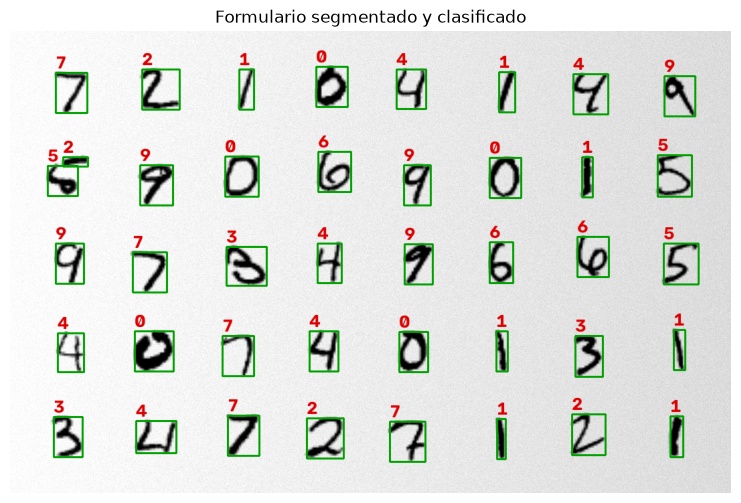

In [ ]:
def demo_formulario(model, x_te, y_te):
    n = 40
    form, gt = make_synthetic_form(x_te[:n], y_te[:n])
    cv2.imwrite(os.path.join(OUT, "formulario_sintetico.png"), form)
    digits, boxes = segment_digits(form)
    if not digits:
        print("No se segmentaron dígitos.")
        return
    pred = model.predict(np.array(digits)[..., None], verbose=0).argmax(1)
    vis = cv2.cvtColor(form, cv2.COLOR_GRAY2BGR)
    for (x, y, w, h), p in zip(boxes, pred):
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 160, 0), 2)
        cv2.putText(vis, str(p), (x, max(15, y - 6)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.9, (0, 0, 220), 2)
    cv2.imwrite(os.path.join(OUT, "formulario_segmentado.png"), vis)
    # El orden de lectura (filas, izq->der) coincide con el de colocación.
    if len(pred) == len(gt):
        acc = float(np.mean(pred == np.array(gt)))
        print(f"Demo formulario: {len(pred)} dígitos segmentados, exactitud={acc:.3f}")
    else:
        print(f"Demo formulario: segmentados {len(pred)} de {len(gt)} (revisar umbral/min_area)")


demo_formulario(model, x_te, y_te)
vis = cv2.cvtColor(cv2.imread(os.path.join(OUT, "formulario_segmentado.png")), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 6)); plt.imshow(vis); plt.axis("off"); plt.title("Formulario segmentado y clasificado"); plt.show()

## 8. Conclusiones

1. La CNN fue el mejor modelo (99,18 % en test) y superó a SVM, KNN y regresión
   logística bajo el mismo protocolo, por lo que se recomienda como clasificador
   principal para TecnoForms.
2. Los modelos clásicos son una referencia válida: SVM (98,68 %) es la mejor
   alternativa si no se dispone de recursos para entrenar una red; KNN (97,60 %) es
   más lento al predecir; la regresión logística (92,59 %) es solo una línea base.
3. El preprocesamiento y la segmentación son tan críticos como el modelo: el demo con
   formulario sintético alcanzó [COMPLETA: exactitud del demo].
4. Mejor configuración hallada por validación cruzada: [COMPLETA: línea
   "Mejor configuración"].
5. Limitaciones: MNIST es más limpio que un formulario real, y la evaluación fue una
   sola corrida; en producción convendría reentrenar con muestras reales de TecnoForms
   y mantener un umbral de confianza con revisión humana para los dígitos dudosos.
6. Mejoras propuestas: más aumento de datos, separación de dígitos pegados,
   ensemble de CNN y reentrenamiento con los casos corregidos.